# Movie Industry Analysis: Trends in Genres and Actors (1980–2020s)

## Project Overview

The analysis focuses on movie genre trends, actor appearances, and genre composition across movies released from the 1980s through the 2020s.

The goal is to identify key trends in the dataset, visualize patterns over time, and demonstrate practical exploratory data analysis (EDA) skills.

## Key Research Questions

1. Which movie genres appear most frequently in the dataset?
2. How has the number of movies in the leading genres changed over time?
3. Which actors have the highest number of movie appearances?
4. How have appearances of the most frequently featured actors changed over time?
5. What proportion of movies featuring the top actors belong to the three most common genres?

## Tools and Technologies

- Python
- Pandas and NumPy
- Matplotlib
- Jupyter Notebook

## Data Source

Wikipedia Movie Data, available on [GitHub](https://github.com/prust/wikipedia-movie-data).

The analysis uses movie records from the 1980s through the 2020s. The dataset is based on Wikipedia movie records and should not be treated as a complete representation of all movies released worldwide.

In [1]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 1. Data Loading

The dataset is sourced from the Wikipedia Movie Data repository on GitHub.

Movie records are loaded from JSON files covering five decades, from the 1980s through the 2020s. The files are processed and combined into a single Pandas DataFrame for further analysis.

In [2]:
indexes = np.arange(1980, 2021, 10)
json_files = [f'movies-{i}s.json' for i in indexes]
json_dir = 'https://raw.githubusercontent.com/prust/wikipedia-movie-data/refs/heads/master/'
dataframes = []

## 2. Data Cleaning and Preparation

The JSON files are loaded individually and combined into a single dataset.

During the initial cleaning process:

- Unnecessary metadata columns are removed.
- Data from all successfully loaded files is concatenated into one DataFrame.

Additional data quality checks will be performed to identify duplicates, missing values, and potential inconsistencies.

In [3]:

dataframes = []
cleaning_stats = []

for file in json_files:
    file_path = json_dir + file

    try:
        df = pd.read_json(file_path)
    except Exception as e:
        print(f'Could not read {file_path}: {e}')
        continue

    drop_columns = [
        'href', 'extract', 'thumbnail',
        'thumbnail_width', 'thumbnail_height'
    ]

    df = df.drop(columns=drop_columns, errors='ignore')

    rows_before = len(df)
    missing_values = df.isna().sum().to_dict()

    rows_after = len(df)

    cleaning_stats.append({
        'file': file,
        'rows_before': rows_before,
        'rows_after': rows_after,
        'rows_removed': rows_before - rows_after,
        'missing_values': missing_values
    })

    dataframes.append(df)

combined = pd.concat(dataframes, ignore_index=True)

# Remove exact duplicate movie records
combined = combined.loc[
    ~combined.assign(
        cast=combined['cast'].apply(tuple),
        genres=combined['genres'].apply(tuple)
    ).duplicated()
].reset_index(drop=True)

print(f'Cleaned dataset: {combined.shape[0]} movies')

cleaning_report = pd.DataFrame(cleaning_stats)
cleaning_report

Cleaned dataset: 11215 movies


,file,rows_before,rows_after,rows_removed,missing_values
0,movies-1980s.json,2272,2272,0,"{'title': 0, 'year': 0, 'cast': 0, 'genres': 0}"
1,movies-1990s.json,2849,2849,0,"{'title': 0, 'year': 0, 'cast': 0, 'genres': 0}"
2,movies-2000s.json,2430,2430,0,"{'title': 0, 'year': 0, 'cast': 0, 'genres': 0}"
3,movies-2010s.json,2512,2512,0,"{'title': 0, 'year': 0, 'cast': 0, 'genres': 0}"
4,movies-2020s.json,1153,1153,0,"{'title': 0, 'year': 0, 'cast': 0, 'genres': 0}"


### Dataset Validation

In [4]:
combined.shape

(11215, 4)

In [5]:
combined.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11215 entries, 0 to 11214
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   title   11215 non-null  object
 1   year    11215 non-null  int64 
 2   cast    11215 non-null  object
 3   genres  11215 non-null  object
dtypes: int64(1), object(3)
memory usage: 350.6+ KB


In [6]:
combined.isna().sum()

title     0
year      0
cast      0
genres    0
dtype: int64

In [7]:
empty_cast = combined['cast'].apply(
    lambda x: isinstance(x, list) and len(x) == 0
)

empty_genres = combined['genres'].apply(
    lambda x: isinstance(x, list) and len(x) == 0
)

print('Empty cast:', empty_cast.sum())
print('Empty genres:', empty_genres.sum())
print('Both empty:', (empty_cast & empty_genres).sum())
print('At least one empty:', (empty_cast | empty_genres).sum())

Empty cast: 314
Empty genres: 210
Both empty: 33
At least one empty: 491


### Data Quality Summary

The initial dataset contained 11,216 movie records across four columns: `title`, `year`, `cast`, and `genres`.

**Data quality checks:**

- **Missing values:** No null values were found in the four retained columns.
- **Duplicate records:** One exact duplicate was identified and removed.
- **Empty cast lists:** 314 records (2.80%).
- **Empty genre lists:** 210 records (1.87%).
- **Both lists empty:** 33 records.
- **At least one empty list:** 491 records (4.38%).

**Cleaning decisions:**

- Removed one exact duplicate to prevent double-counting.
- Retained records with empty cast or genre lists to avoid unnecessary data loss.
- Records with empty genre lists will be excluded only from genre-specific analyses.
- Records with empty cast lists will be excluded only from actor-specific analyses.

**Final dataset:** 11,215 unique movie records across four columns.

**Data limitation:** The dataset is based on Wikipedia movie records and may not represent the complete global film industry.

### Data Preview

In [8]:
df = combined

In [9]:
df.head()

,title,year,cast,genres
0,Airplane!,1980,"[Robert Hays, Julie Hagerty, Leslie Nielsen, P...","[Comedy, Satire]"
1,Alex and the Doberman Gang,1980,"[Jack Stauffer, Taurean Blacque, Cindy Acker]","[Action, Comedy, Family]"
2,Alien Dead,1980,[Buster Crabbe],"[Science Fiction, Horror]"
3,Alligator,1980,"[Robert Forster, Robin Riker, Henry Silva, Dea...","[Horror, Independent]"
4,Altered States,1980,"[William Hurt, Blair Brown]","[Science Fiction, Horror]"


## 3. Exploratory Data Analysis

### 3.1. Top 10 Movie Genres

This section identifies the ten most frequently represented movie genres in the dataset.

Since each movie can belong to multiple genres, the `genres` column is expanded using `explode()` to create one row per movie-genre combination.

The analysis counts movie records associated with each genre and visualizes the results using a bar chart.

In [10]:

df_exploded = df.explode('genres')
df_exploded = df_exploded[df_exploded['genres'].notna()]
df_exploded.head()

,title,year,cast,genres
0,Airplane!,1980,"[Robert Hays, Julie Hagerty, Leslie Nielsen, P...",Comedy
0,Airplane!,1980,"[Robert Hays, Julie Hagerty, Leslie Nielsen, P...",Satire
1,Alex and the Doberman Gang,1980,"[Jack Stauffer, Taurean Blacque, Cindy Acker]",Action
1,Alex and the Doberman Gang,1980,"[Jack Stauffer, Taurean Blacque, Cindy Acker]",Comedy
1,Alex and the Doberman Gang,1980,"[Jack Stauffer, Taurean Blacque, Cindy Acker]",Family


In [11]:

top10_genres = df_exploded.groupby('genres').agg(movies_count=('title', 'count')).sort_values('movies_count', ascending=False).reset_index().head(10)
top10_genres

,genres,movies_count
0,Comedy,3995
1,Drama,3800
2,Action,1537
3,Thriller,1430
4,Horror,1186
5,Romance,1113
6,Science Fiction,781
7,Crime,741
8,Fantasy,580
9,Animated,558


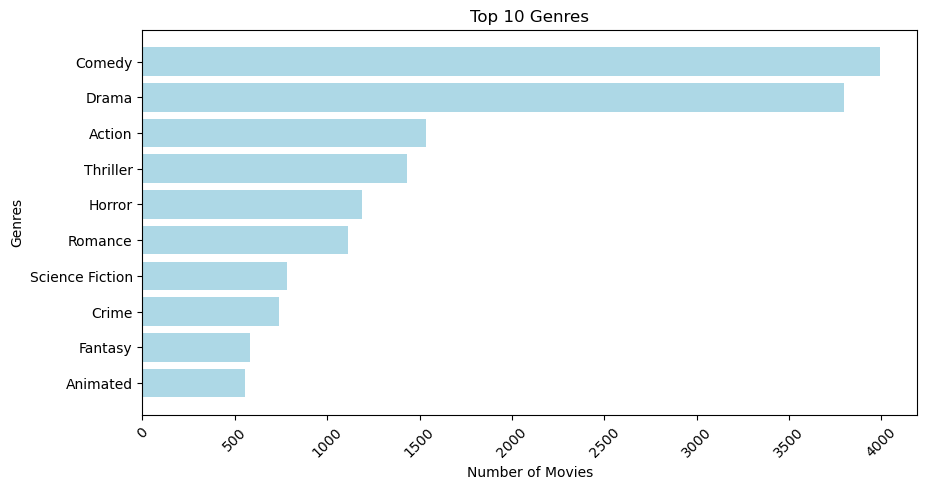

In [12]:

plt.figure(figsize=(10,5))
plt.barh(top10_genres['genres'], top10_genres['movies_count'] ,color='lightblue')
plt.gca().invert_yaxis()
plt.title('Top 10 Genres')
plt.xticks(rotation=45)
plt.xlabel('Number of Movies')
plt.ylabel('Genres')
plt.show()

#### Key Findings

- **Comedy (3,995)** and **Drama (3,800)** are the most frequently represented genres in the dataset.
- **Action (1,537)** ranks third, with substantially fewer movie records than the two leading genres.
- A movie may belong to multiple genres, so genre counts are not mutually exclusive.
- These results describe genre representation in the dataset rather than audience preferences or commercial performance.

### 3.2. Genre Trends Over Time

This section examines how the annual number of movie records changed for the three most frequently represented genres: Comedy, Drama, and Action.

The analysis groups movies by release year and genre to compare trends over time.

**Note:** The results reflect the coverage of the Wikipedia-based dataset rather than the complete number of movies released worldwide.

In [13]:

top3_genres = top10_genres[:3]

top3_genres

,genres,movies_count
0,Comedy,3995
1,Drama,3800
2,Action,1537


In [14]:

df_top = df_exploded[df_exploded['genres'].isin(top3_genres['genres'])]
df_top.head()

,title,year,cast,genres
0,Airplane!,1980,"[Robert Hays, Julie Hagerty, Leslie Nielsen, P...",Comedy
1,Alex and the Doberman Gang,1980,"[Jack Stauffer, Taurean Blacque, Cindy Acker]",Action
1,Alex and the Doberman Gang,1980,"[Jack Stauffer, Taurean Blacque, Cindy Acker]",Comedy
5,Amber Waves,1980,"[Dennis Weaver, Kurt Russell, Fran Brill, Wilf...",Drama
6,American Gigolo,1980,"[Richard Gere, Lauren Hutton, Héctor Elizondo]",Drama


In [15]:

trend = df_top.groupby(['year', 'genres']).size().reset_index(name = 'movies_count').sort_values('year') 
trend.head(10)

,year,genres,movies_count
0,1980,Action,24
1,1980,Comedy,78
2,1980,Drama,51
3,1981,Action,18
4,1981,Comedy,55
5,1981,Drama,49
6,1982,Action,17
7,1982,Comedy,59
8,1982,Drama,42
9,1983,Action,16


In [16]:

trend_pivot = trend.pivot(index='year', columns='genres', values='movies_count')
trend_pivot.head(10)

genres,Action,Comedy,Drama
year,,,
1980,24,78,51
1981,18,55,49
1982,17,59,42
1983,16,45,60
1984,23,71,71
1985,32,74,58
1986,48,80,68
1987,42,122,93
1988,46,113,112


In [17]:
trend_pivot.isna().sum()

genres
Action    0
Comedy    0
Drama     0
dtype: int64

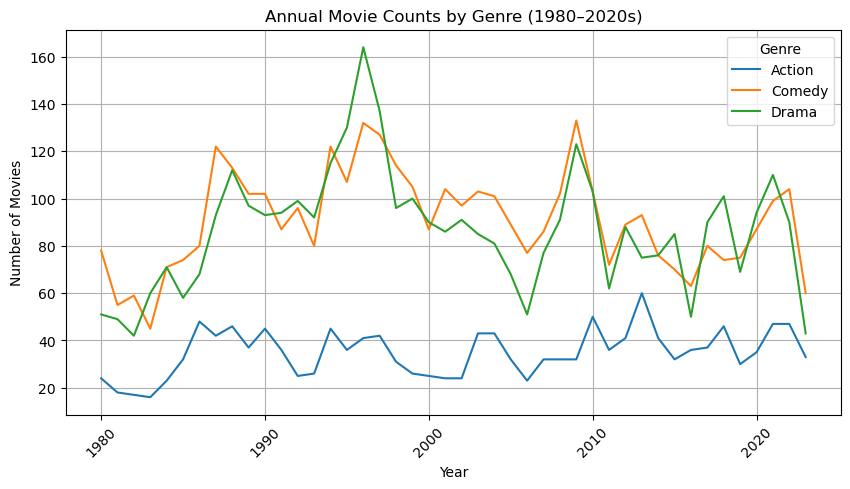

In [18]:

trend_pivot.plot(figsize=(10,5))
plt.title('Annual Movie Counts by Genre (1980–2020s)')
plt.xticks(rotation=45)
plt.xlabel('Year')
plt.ylabel('Number of Movies')
plt.legend(title='Genre')
plt.grid(True)
plt.show()

In [19]:
peak_year = trend[trend['movies_count'] == trend.groupby('genres')['movies_count'].transform('max')]
peak_year

,year,genres,movies_count
50,1996,Drama,164
88,2009,Comedy,133
99,2013,Action,60


#### Key Findings — Genre Trends Over Time

- **Drama** reached its highest annual count in 1996, with 164 movie records.
- **Comedy** peaked in 2009, with 133 movie records.
- **Action** reached its maximum in 2013, with 60 movie records.
- The three genres reached their peaks in different years, indicating differences in their representation over time.
- These findings reflect the distribution of movies in the dataset and should not be interpreted as changes in global film production or audience demand.

### 3.3. Top 10 Actors by Movie Count

This section identifies the ten actors with the highest number of movie appearances in the dataset.

Since each movie contains a list of cast members, the `cast` column is expanded using `explode()` to create one row per movie-actor combination.

The analysis counts movie records associated with each actor and identifies the most frequently represented performers.

In [20]:
# Select movie and cast data to avoid duplicating actor appearances across genres
df_cast = df[['title', 'year', 'cast']]
df_cast.head()

,title,year,cast
0,Airplane!,1980,"[Robert Hays, Julie Hagerty, Leslie Nielsen, P..."
1,Alex and the Doberman Gang,1980,"[Jack Stauffer, Taurean Blacque, Cindy Acker]"
2,Alien Dead,1980,[Buster Crabbe]
3,Alligator,1980,"[Robert Forster, Robin Riker, Henry Silva, Dea..."
4,Altered States,1980,"[William Hurt, Blair Brown]"


In [21]:

df_cast_exploded = df_cast.explode('cast')
df_cast_exploded = df_cast_exploded[df_cast_exploded['cast'].notna()]
df_cast_exploded.head()

,title,year,cast
0,Airplane!,1980,Robert Hays
0,Airplane!,1980,Julie Hagerty
0,Airplane!,1980,Leslie Nielsen
0,Airplane!,1980,Peter Graves
0,Airplane!,1980,Robert Stack


In [22]:

top10_actors = df_cast_exploded.groupby('cast')['title'].agg(movies_count=('count')).sort_values('movies_count', ascending=False).reset_index().head(10)
top10_actors

,cast,movies_count
0,Bruce Willis,104
1,Samuel L. Jackson,95
2,Robert De Niro,78
3,Morgan Freeman,72
4,Nicolas Cage,71
5,Liam Neeson,71
6,Dennis Quaid,69
7,Willem Dafoe,69
8,John Goodman,67
9,Julianne Moore,65


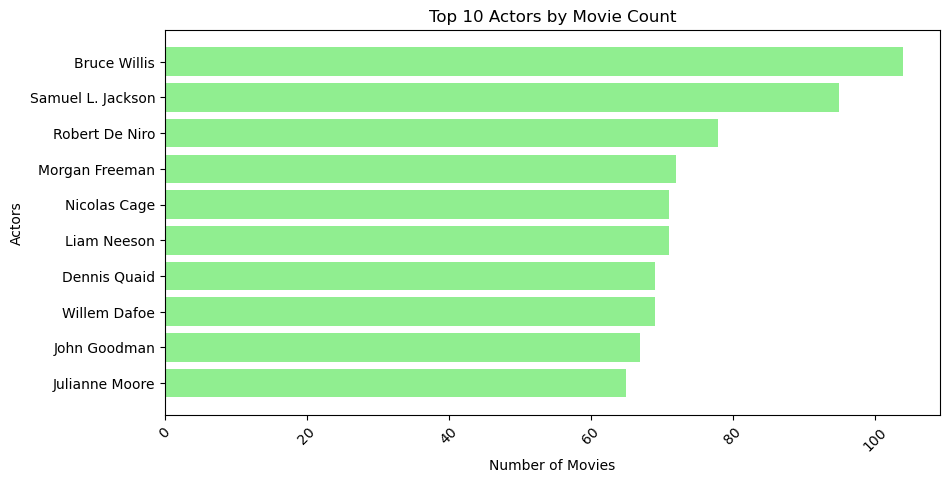

In [23]:

plt.figure(figsize=(10,5))
plt.barh(top10_actors['cast'], top10_actors['movies_count'] ,color='lightgreen')
plt.gca().invert_yaxis()
plt.title('Top 10 Actors by Movie Count')
plt.xticks(rotation=45)
plt.xlabel('Number of Movies')
plt.ylabel('Actors')
plt.show()

#### Key Findings — Actor Representation

- **Bruce Willis** has the highest number of movie appearances in the dataset (104), followed by **Samuel L. Jackson** (95) and **Robert De Niro** (78).
- **Nicolas Cage** and **Liam Neeson** each appear in 71 movie records.
- **Dennis Quaid** and **Willem Dafoe** each appear in 69 movie records.
- These counts reflect actor representation in the dataset and do not necessarily correspond to their complete filmographies.

### 3.4. Actor Trends Over Time

This section examines the annual number of movie appearances for the three most frequently represented actors in the dataset.

The analysis groups movie records by release year and actor to compare their representation over time.

**Note:** The results reflect the coverage of the dataset and should not be interpreted as complete actor filmographies or measures of audience popularity.

In [24]:

top3_actors = top10_actors[:3]

top3_actors

,cast,movies_count
0,Bruce Willis,104
1,Samuel L. Jackson,95
2,Robert De Niro,78


In [25]:

df_top_cast = df_cast_exploded[df_cast_exploded['cast'].isin(top3_actors['cast'])]
df_top_cast.head()

,title,year,cast
152,Raging Bull,1980,Robert De Niro
371,True Confessions,1981,Robert De Niro
611,The King of Comedy,1983,Robert De Niro
767,Falling in Love,1984,Robert De Niro
837,Once Upon a Time in America,1984,Robert De Niro


In [26]:

trend_cast = df_top_cast.groupby(['year', 'cast']).size().reset_index( name = 'movies_count').sort_values('year')
trend_cast.head(10)

,year,cast,movies_count
0,1980,Robert De Niro,1
1,1981,Robert De Niro,1
2,1983,Robert De Niro,1
3,1984,Robert De Niro,2
4,1985,Robert De Niro,1
5,1986,Robert De Niro,1
6,1987,Bruce Willis,1
7,1987,Robert De Niro,2
8,1988,Bruce Willis,2
9,1988,Robert De Niro,1


In [27]:
# Include all years in the dataset, filling missing actor-year counts with zero
trend_pivot_cast = trend_cast.pivot(index='year', columns='cast', values='movies_count').reindex(range(df['year'].min(), df['year'].max() + 1)).fillna(0).astype(int)
trend_pivot_cast.head(10)

cast,Bruce Willis,Robert De Niro,Samuel L. Jackson
year,,,
1980,0,1,0
1981,0,1,0
1982,0,0,0
1983,0,1,0
1984,0,2,0
1985,0,1,0
1986,0,1,0
1987,1,2,0
1988,2,1,0


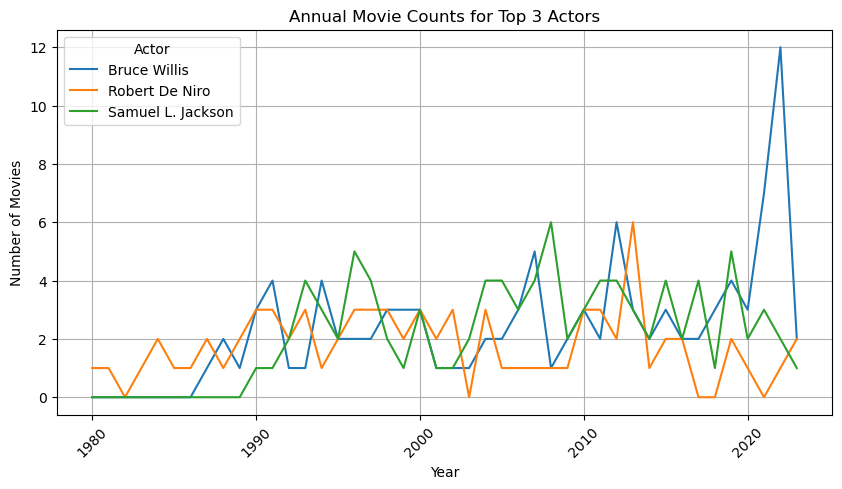

In [28]:

trend_pivot_cast.plot(figsize=(10,5))
plt.title('Annual Movie Counts for Top 3 Actors')
plt.xticks(rotation=45)
plt.xlabel('Year')
plt.ylabel('Number of Movies')
plt.legend(title='Actor')
plt.grid(True)
plt.show()

In [29]:
peak_years_cast = trend_cast[trend_cast['movies_count'] == trend_cast.groupby('cast')['movies_count'].transform('max')]
peak_years_cast

,year,cast,movies_count
67,2008,Samuel L. Jackson,6
81,2013,Robert De Niro,6
104,2022,Bruce Willis,12


#### Key Findings — Actor Trends Over Time

- **Bruce Willis** reached his highest annual movie count in 2022, appearing in 12 movie records.
- **Samuel L. Jackson** reached his peak in 2008, with 6 movie records.
- **Robert De Niro** reached his peak in 2013, also with 6 movie records.
- Bruce Willis's highest annual count was twice that of either of the other two actors.
- These findings reflect actor representation in the dataset rather than complete filmographies or measures of professional success.

### 3.5. Actor–Genre Analysis

This section examines the genre composition of movies featuring the ten most frequently represented actors in the dataset.

Movies are classified into two groups:
- **Top 3 Genres:** Movies belonging to at least one of the three most common genres (Comedy, Drama, or Action).
- **Other Genres:** Movies that do not belong to any of these three genres.

The analysis compares both absolute movie counts and the percentage of each actor's movies belonging to the top three genres.

Each movie is counted once per actor, even if it belongs to multiple selected genres.

In [30]:

top_actors = top10_actors['cast'].tolist()
top_genres = top10_genres['genres'].head(3).tolist()

In [31]:

df_top = df[df['cast'].apply(lambda x: any(actor in x for actor in top_actors))]


print(df_top.shape)
df_top.head()

(722, 4)


,title,year,cast,genres
77,Gorp,1980,"[Dennis Quaid, Michael Lembeck, Rosanna Arquette]",[Comedy]
113,The Long Riders,1980,"[David Carradine, Keith Carradine, Robert Carr...",[Western]
152,Raging Bull,1980,"[Robert De Niro, Joe Pesci, Cathy Moriarty]","[Biography, Sports, Drama]"
205,All Night Long,1981,"[Gene Hackman, Barbra Streisand, Diane Ladd, D...","[Comedy, Romance]"
227,Caveman,1981,"[Ringo Starr, Dennis Quaid, Shelley Long, Barb...",[Comedy]


In [32]:
# Classify each actor-movie appearance by whether the movie belongs to any of the top 3 genres
rows=[]
for _, row in df_top.iterrows():
    for actor in row['cast']:
        if actor in top_actors:
            if any(g in top_genres for g in row['genres']):
                rows.append({'actor':actor, 'genre_group':'top 3 genres'})
            else:
                rows.append({'actor':actor, 'genre_group':'other genres'})

pairs_df = pd.DataFrame(rows)

In [33]:

actor_stats = (pairs_df.groupby(['actor', 'genre_group']).size().unstack(fill_value=0).reset_index())

actor_stats

genre_group,actor,other genres,top 3 genres
0,Bruce Willis,16,88
1,Dennis Quaid,14,55
2,John Goodman,11,56
3,Julianne Moore,17,48
4,Liam Neeson,17,54
5,Morgan Freeman,24,48
6,Nicolas Cage,21,50
7,Robert De Niro,15,63
8,Samuel L. Jackson,40,55
9,Willem Dafoe,30,39


In [34]:

actor_stats['total'] = actor_stats['top 3 genres'] + actor_stats['other genres']
actor_stats['share_top3_%'] = round(actor_stats['top 3 genres'] / actor_stats['total']*100, 1)
actor_stats = actor_stats.sort_values('share_top3_%', ascending=False)
actor_stats

genre_group,actor,other genres,top 3 genres,total,share_top3_%
0,Bruce Willis,16,88,104,84.6
2,John Goodman,11,56,67,83.6
7,Robert De Niro,15,63,78,80.8
1,Dennis Quaid,14,55,69,79.7
4,Liam Neeson,17,54,71,76.1
3,Julianne Moore,17,48,65,73.8
6,Nicolas Cage,21,50,71,70.4
5,Morgan Freeman,24,48,72,66.7
8,Samuel L. Jackson,40,55,95,57.9
9,Willem Dafoe,30,39,69,56.5


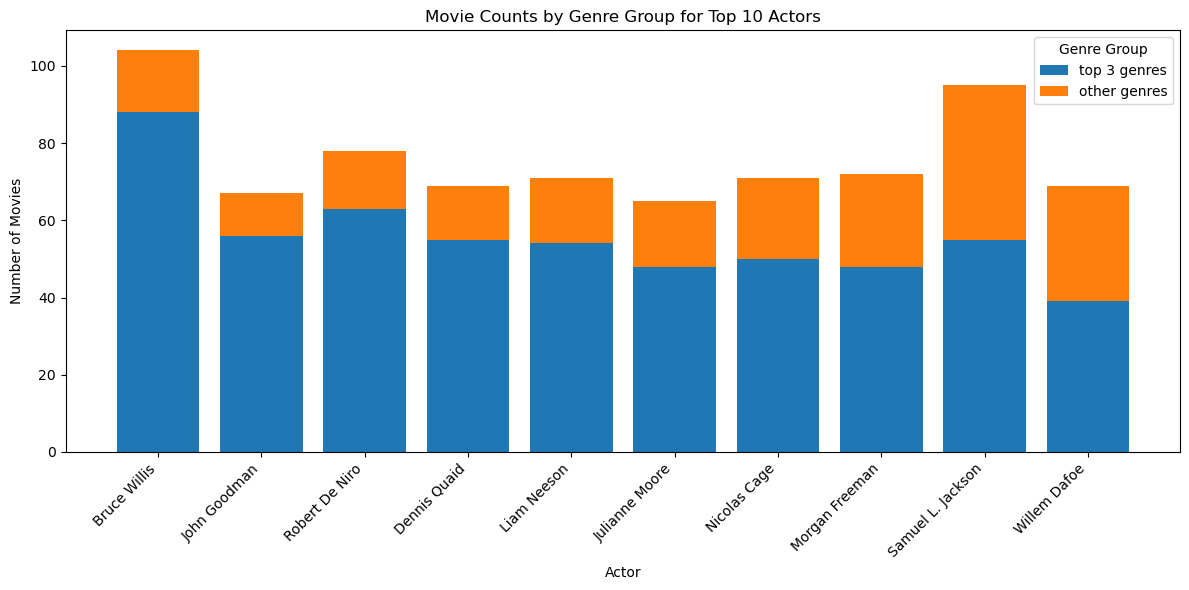

In [35]:

plt.figure(figsize=(12, 6))
plt.bar(actor_stats['actor'], actor_stats['top 3 genres'], label='top 3 genres')
plt.bar(actor_stats['actor'], actor_stats['other genres'], bottom=actor_stats['top 3 genres'], label='other genres')
plt.title('Movie Counts by Genre Group for Top 10 Actors')
plt.xlabel('Actor')
plt.ylabel('Number of Movies')
plt.legend(title='Genre Group')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

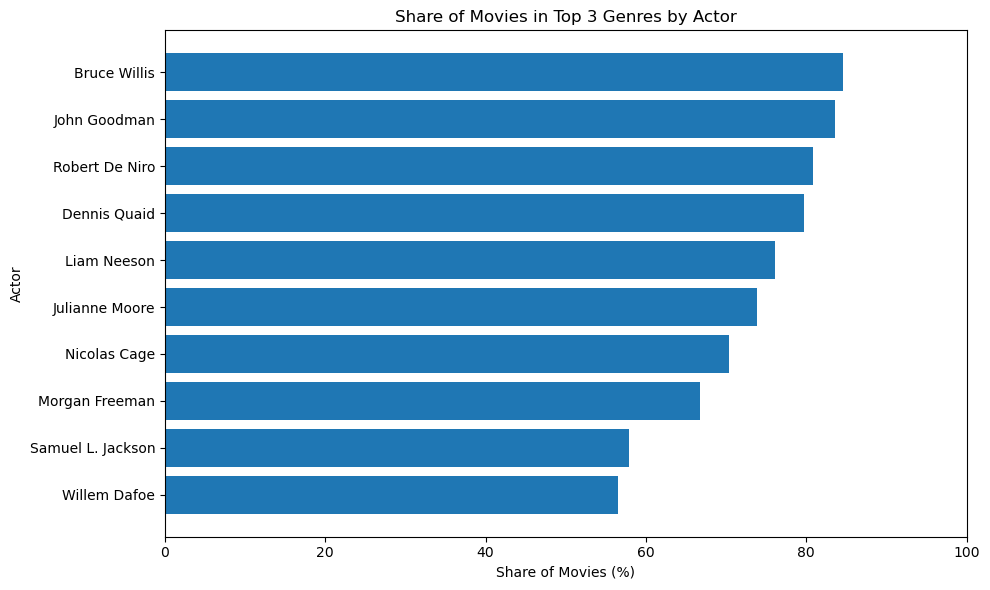

In [36]:
plt.figure(figsize=(10, 6))

plt.barh(
    actor_stats['actor'],
    actor_stats['share_top3_%']
)

plt.gca().invert_yaxis()

plt.title('Share of Movies in Top 3 Genres by Actor')
plt.xlabel('Share of Movies (%)')
plt.ylabel('Actor')
plt.xlim(0, 100)

plt.tight_layout()
plt.show()

#### Key Findings — Actor–Genre Analysis

- **Bruce Willis** had the highest share of movies in the three most common genres (Comedy, Drama, and Action), at **84.6%**.
- **John Goodman (83.6%)** and **Robert De Niro (80.8%)** also had more than 80% of their movies represented in these genres.
- **Willem Dafoe (56.5%)** and **Samuel L. Jackson (57.9%)** had the lowest shares among the ten selected actors.
- The difference between the highest and lowest shares was **28.1 percentage points**, indicating variation in the genre composition of movies featuring these actors.
- Movies were classified as belonging to the top three genres if they had **at least one** of the selected genre labels. Each movie was counted only once per actor, regardless of how many selected genres it included.

**Note:** These findings are based on the available dataset and do not necessarily represent the actors' complete filmographies.

## 4. Conclusion

This project analyzed movie records from the 1980s through the 2020s to explore genre distribution, annual movie counts, actor appearances, and actor–genre relationships.

### Main Findings

- **Genre distribution:** Comedy (3,995 movies) and Drama (3,800 movies) were the most frequently represented genres in the dataset.
- **Genre trends:** Drama reached its highest annual count in 1996 (164 movies), Comedy in 2009 (133 movies), and Action in 2013 (60 movies).
- **Actor representation:** Bruce Willis (104 movies), Samuel L. Jackson (95), and Robert De Niro (78) were the three most frequently represented actors.
- **Actor trends:** Bruce Willis reached his highest annual count in 2022 (12 movies), while Samuel L. Jackson and Robert De Niro peaked at 6 movies in 2008 and 2013, respectively.
- **Actor–genre relationships:** Bruce Willis had the highest share of movies belonging to at least one of the three most common genres (84.6%), while Willem Dafoe had the lowest (56.5%) among the ten selected actors.

### Limitations

The analysis is based on a specific movie dataset and does not represent the entire global film industry. Movies may belong to multiple genres, and the results depend on the completeness and classification of the source records.

### Skills Demonstrated

Python, Pandas, data cleaning, exploratory data analysis (EDA), grouping and aggregation, time-series analysis, data visualization with Matplotlib, and interpretation of analytical results.